# Task 5 — Feature Engineering & Feature Selection
### UniMatch AI — 10-Task Computational Intelligence Pipeline

**Input:** Clean datasets from Task 4 (`university_master_clean.csv`, `graduate_admission_clean.csv`)

**Steps:** Derived feature generation (Fit Score, Affordability Index, Admit-Chance Index, Rank-Tier) → Encoding categorical attributes → Correlation analysis → Feature importance ranking → Feature selection

**Deliverables:** Feature Engineering Report, Feature Matrix, Correlation Matrix, Feature Importance Report, Selected Features

> **Note on data:** the merged applicant-university dataset (`university_master_clean.csv`) does not contain a tuition/fee or country column, so a literal "Affordability Index" and country-based encoding can't be computed from it as-is. This notebook builds the closest honest equivalents from what's actually in the data (using `avg_rank_all3`/`total_students`/`intl_students_pct` as cost-adjacent proxies) and says so explicitly in the Feature Engineering Report rather than faking numbers. If you have a fee/country table, drop it in the "optional" cell in Section 1 and it will be joined in automatically.

## 0. Setup

In [ ]:
import importlib, subprocess, sys

# Only install what's missing instead of uninstalling/force-reinstalling everything.
# The previous force-reinstall of numpy/pandas/scikit-learn routinely crashed the
# Colab runtime (binary incompatibility) and required a manual restart, which broke
# every cell below it. Installing only if a package is missing is safe and fast.
required = ['pandas', 'numpy', 'scipy', 'sklearn', 'matplotlib', 'seaborn']
pip_names = {'sklearn': 'scikit-learn'}
for pkg in required:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pip_names.get(pkg, pkg)])

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from sklearn.model_selection import train_test_split

pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42


## 1. Load Task 4 outputs

Upload `university_master_clean.csv` and `graduate_admission_clean.csv` to the Colab file browser (left sidebar) before running, or mount Drive and adjust the paths.

In [ ]:
import os
DRIVE_DIR = '/content/drive/MyDrive/UniMatch'
# Task 4 writes its CSVs to ./outputs - if Task 4 ran in this same Colab session they are found there,
# so nothing has to be uploaded (browser uploads of large CSVs can get cut off part-way).
SEARCH_DIRS = ['.', './outputs', DRIVE_DIR, f'{DRIVE_DIR}/outputs']

def find_file(name):
    for d in SEARCH_DIRS:
        p = os.path.join(d, name)
        if os.path.exists(p):
            return p
    try:
        from google.colab import files
        print(f"'{name}' not found - please upload it (or run Task 4 in this session first):")
        files.upload()
        return name
    except ModuleNotFoundError:
        raise FileNotFoundError(f"Could not find '{name}' in {SEARCH_DIRS}.")

uni_path = find_file('university_master_clean (1).csv')
grad_path = find_file('graduate_admission_clean (1).csv')   # unscaled: scaling happens in Task 6 on the train split

uni_df = pd.read_csv(uni_path, low_memory=False)
grad_df = pd.read_csv(grad_path)

# Integrity check: Task 4 leaves no missing values in 'admit'. Missing values here mean the CSV was
# cut off during upload -> stop instead of silently training on part of the data.
n_bad = int(uni_df['admit'].isna().sum())
if n_bad:
    raise ValueError(f"{n_bad} row(s) of university_master_clean.csv have no 'admit' value - the file is truncated "
                     f"(only {len(uni_df)} rows loaded; the full file has ~53,500). Re-run Task 4 in this session "
                     "or copy the file via Google Drive instead of uploading it.")

print('university_master_clean:', uni_df.shape, 'from', uni_path)
print('graduate_admission_clean:', grad_df.shape, 'from', grad_path)
uni_df.head()

university_master_clean: (53527, 54) from ./university_master_clean (1).csv
graduate_admission_clean: (500, 9) from ./graduate_admission_clean (1).csv


,username,major,researchexp,industryexp,specialization,toeflscore,program,department,internexp,grev,greq,userprofilelink,journalpubs,grea,toppercgpa,termandyear,confpubs,ugcollege,cgpa,cgpascale,univname,admit,univ_key,university,country,region,university_type,qs_rank_2026,the_rank_2026,arwu_rank_2025,qs_score,the_score,arwu_score,qs_academic_rep,qs_employer_rep,qs_faculty_student,qs_citations,qs_intl_faculty,qs_intl_students,the_teaching,the_research_env,the_research_quality,the_industry,the_intl_outlook,founded,total_students,intl_students_pct,nobel_laureates,fields_medalists,ranked_in_all_3,avg_rank_all3,university_age_2026,data_sources,is_ranked
0,143saf,Systems and Control,0,18,Robotics,112.0,MS,Instrumentation & Control,5.0,160.0,167.0,http://www.edulix.com/unisearch/user.php?uid=2...,0.0,4.5,8.9,Fall - 2015,0.0,Dharamsinh Desai University,8.50,10.0,Worcester Polytechnic Institute,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
1,7790ashish,Manufacturing Engineering,0,0,VLSI,106.0,MS,0,0.0,153.0,166.0,http://www.edulix.com/unisearch/user.php?uid=1...,0.0,3.5,0.0,Fall - 2013,0.0,MU,58.00,100.0,Worcester Polytechnic Institute,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
2,AB25,(MIS / MSIM / MSIS / MSIT),0,66,VLSI,94.0,MS,Computer Engineering,0.0,146.0,157.0,http://www.edulix.com/unisearch/user.php?uid=2...,0.0,3.0,81.0,Fall - 2015,0.0,IET DAVV,78.28,100.0,Worcester Polytechnic Institute,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3,abhijitg,Computer Science,0,0,VLSI,106.0,MS,0,0.0,153.0,166.0,http://www.edulix.com/unisearch/user.php?uid=1...,0.0,3.5,0.0,Fall - 2013,0.0,MU,58.00,100.0,Worcester Polytechnic Institute,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
4,abhijitgang,MIS,0,0,VLSI,81.0,MS,computer,0.0,145.0,168.0,http://www.edulix.com/unisearch/user.php?uid=1...,0.0,2.5,70.0,Fall - 2011,0.0,Pune University,57.00,100.0,Worcester Polytechnic Institute,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0


In [ ]:
# OPTIONAL: join an external country / tuition-fee lookup table here if you have one,
# e.g. a CSV with columns [univname, country, avg_tuition_usd].
# fees_df = pd.read_csv('university_fees_country.csv')
# uni_df = uni_df.merge(fees_df, on='univname', how='left')
uni_df.columns.tolist()


['username',
 'major',
 'researchexp',
 'industryexp',
 'specialization',
 'toeflscore',
 'program',
 'department',
 'internexp',
 'grev',
 'greq',
 'userprofilelink',
 'journalpubs',
 'grea',
 'toppercgpa',
 'termandyear',
 'confpubs',
 'ugcollege',
 'cgpa',
 'cgpascale',
 'univname',
 'admit',
 'univ_key',
 'university',
 'country',
 'region',
 'university_type',
 'qs_rank_2026',
 'the_rank_2026',
 'arwu_rank_2025',
 'qs_score',
 'the_score',
 'arwu_score',
 'qs_academic_rep',
 'qs_employer_rep',
 'qs_faculty_student',
 'qs_citations',
 'qs_intl_faculty',
 'qs_intl_students',
 'the_teaching',
 'the_research_env',
 'the_research_quality',
 'the_industry',
 'the_intl_outlook',
 'founded',
 'total_students',
 'intl_students_pct',
 'nobel_laureates',
 'fields_medalists',
 'ranked_in_all_3',
 'avg_rank_all3',
 'university_age_2026',
 'data_sources',
 'is_ranked']

## 2. Derived Feature Generation

Dataset A (`uni_df`) is applicant-level, joined to the university the applicant applied to, with `admit` (0/1) as the outcome. We engineer:

- **Rank-Tier** — Tier 1 (rank ≤ 10), Tier 2 (11-25), Tier 3 (26-50), Tier 4 (> 50) from `avg_rank_all3`; rows whose university is not in the rankings file get **Unranked** (uses the `is_ranked` flag from Task 4)
- **Admit-Chance Index** — a 0–1 composite of the applicant's academic strength (CGPA %, GRE-Q, GRE-V, TOEFL, research/industry exp), built without looking at the outcome
- **Fit Score** — how close the applicant's profile is to the typical *admitted* profile at that university. Because it uses the `admit` label, the admitted-cohort statistics are computed from the **training split only** (the split is saved and reused in Task 6), so no test-set outcomes leak into the feature
- **Affordability Index (proxy)** — no fee/cost column exists, so a *resource-availability proxy* from `total_students`, `intl_students_pct` and rank is built for ranked universities only, and clearly labelled as a proxy

Dataset B (`grad_df`) comes with `chance_of_admit` as a continuous target. `university_rating` (1-5) is already an ordinal tier, so it is used directly; we add an **Admit-Chance Index** composite as a cross-check.


In [ ]:
# ---- 2.1 Rank-Tier (Dataset A) ----
# Tiers use FIXED rank bands, one tier per university. (A quantile split over applicant ROWS
# would split applicants of the SAME university into different tiers just by row order.)
# Rows whose university is not in the rankings file (is_ranked == 0) get 'Unranked'.
rank_col = 'avg_rank_all3' if uni_df['avg_rank_all3'].notna().sum() > 0 else 'qs_rank_2026'
TIER_LABELS = ['Tier 1', 'Tier 2', 'Tier 3', 'Tier 4']

tier = pd.cut(uni_df[rank_col], bins=[0, 10, 25, 50, np.inf], labels=TIER_LABELS).astype(object)
tier[uni_df['is_ranked'] != 1] = 'Unranked'
uni_df['rank_tier'] = pd.Categorical(tier, categories=TIER_LABELS + ['Unranked'])

print(f"Rows with a real rank: {int(uni_df['is_ranked'].sum())} / {len(uni_df)} "
      f"({uni_df['is_ranked'].mean()*100:.1f}%)")
uni_df['rank_tier'].value_counts()


Rows with a real rank: 5695 / 53527 (10.6%)


,count
rank_tier,
Unranked,47832
Tier 2,2711
Tier 3,2406
Tier 1,578
Tier 4,0


In [ ]:
# ---- 2.2 Admit-Chance Index (Dataset A) — applicant academic strength, 0-1 ----
strength_cols = ['cgpa', 'cgpascale', 'greq', 'grev', 'grea', 'toeflscore', 'researchexp', 'industryexp']

# Normalise cgpa onto a common 0-100 scale using cgpascale where available
uni_df['cgpa_pct'] = np.where(uni_df['cgpascale'] > 0, (uni_df['cgpa'] / uni_df['cgpascale']) * 100, np.nan)
uni_df['cgpa_pct'] = uni_df['cgpa_pct'].clip(0, 100)

def minmax(s):
    s = s.astype(float)
    lo, hi = s.quantile(0.01), s.quantile(0.99)  # robust to outliers
    return ((s.clip(lo, hi) - lo) / (hi - lo + 1e-9)).fillna(0)

admit_index_components = pd.DataFrame({
    'cgpa_n':        minmax(uni_df['cgpa_pct']),
    'greq_n':        minmax(uni_df['greq']),
    'grev_n':        minmax(uni_df['grev']),
    'toefl_n':       minmax(uni_df['toeflscore']),
    'researchexp_n': minmax(uni_df['researchexp']),
    'industryexp_n': minmax(uni_df['industryexp']),
})
weights = {'cgpa_n': 0.30, 'greq_n': 0.20, 'grev_n': 0.15, 'toefl_n': 0.15, 'researchexp_n': 0.12, 'industryexp_n': 0.08}
uni_df['admit_chance_index'] = sum(admit_index_components[c] * w for c, w in weights.items())
uni_df[['cgpa_pct', 'greq', 'grev', 'toeflscore', 'admit_chance_index']].describe()


,cgpa_pct,greq,grev,toeflscore,admit_chance_index
count,53527.000000,53527.000000,53527.000000,53527.000000,53527.000000
mean,75.290869,164.911876,153.251387,105.360267,0.516235
std,12.262545,4.626928,5.929636,7.307899,0.111303
min,1.000000,136.000000,132.000000,57.000000,0.000000
25%,68.085000,162.000000,149.000000,101.000000,0.441261
50%,76.000000,166.000000,153.000000,106.000000,0.522273
75%,83.500000,169.000000,157.000000,110.000000,0.596270
max,100.000000,170.000000,170.000000,120.000000,0.917662


In [ ]:
# ---- 2.3 Fit Score (Dataset A) — profile distance to each university's admitted-cohort mean ----
# FIX (target leakage): fit_score is built from the `admit` label, so the admitted-cohort mean/std
# must come from TRAINING rows only. We create the train/test split here (saved as a `split`
# column and reused unchanged in Task 6), compute each university's admitted-cohort stats from
# train rows, and apply the SAME stats to every row of that university (train and test).
# The earlier leave-one-out version gave admitted rows slightly different statistics from
# rejected rows at the same university - the model could read `admit` straight off those
# columns, which is why Task 6 reached ROC-AUC = 1.0.
fit_feature_cols = ['cgpa_pct', 'greq', 'grev', 'toeflscore']

uni_df['admit'] = uni_df['admit'].astype(int)   # no NaNs here - checked when the file was loaded

train_idx, test_idx = train_test_split(
    uni_df.index, test_size=0.2, random_state=RANDOM_STATE, stratify=uni_df['admit']
)
uni_df['split'] = 'test'
uni_df.loc[train_idx, 'split'] = 'train'

admitted_train = uni_df[(uni_df['split'] == 'train') & (uni_df['admit'] == 1)]
cohort_mean = admitted_train.groupby('univname')[fit_feature_cols].mean()
cohort_std = admitted_train.groupby('univname')[fit_feature_cols].std()

z_dists = []
for c in fit_feature_cols:
    mu = uni_df['univname'].map(cohort_mean[c])
    sd = uni_df['univname'].map(cohort_std[c]).replace(0, np.nan).fillna(1)
    z_dists.append(((uni_df[c] - mu) / sd).abs())
uni_df['profile_distance'] = pd.concat(z_dists, axis=1).mean(axis=1)
train_median = uni_df.loc[uni_df['split'] == 'train', 'profile_distance'].median()
uni_df['profile_distance'] = uni_df['profile_distance'].fillna(train_median)
uni_df['fit_score'] = 1 / (1 + uni_df['profile_distance'])  # bounded (0,1], higher = closer fit

print(uni_df['split'].value_counts())
uni_df[['univname', 'profile_distance', 'fit_score']].sample(5, random_state=RANDOM_STATE)

split
train    42821
test     10706
Name: count, dtype: int64


,univname,profile_distance,fit_score
16759,University of Illinois Urbana-Champaign,0.647789,0.606874
6939,University of Texas Austin,0.842245,0.542816
50858,Arizona State University,1.134294,0.468539
27811,Texas A and M University College Station,0.562830,0.639865
47287,Cornell University,0.995422,0.501147


In [ ]:
# ---- 2.4 Affordability Index (PROXY — see note in Section 1) ----
# No tuition/fee/country column is present. We approximate "affordability/access" from institution
# scale, international share and rank - NOT a real cost measure. It can only be computed for
# universities that exist in the rankings file, so it is NaN for unranked rows (not faked).
# Min-max scaling is done over the 57 ranked universities, not over applicant rows.
def minmax_ref(s, ref):
    lo, hi = ref.min(), ref.max()
    return (s - lo) / (hi - lo) if hi > lo else s * 0 + 0.5

ref = uni_df[uni_df['is_ranked'] == 1].drop_duplicates('univname')
uni_df['affordability_index_proxy'] = (
    0.4 * minmax_ref(uni_df['total_students'], ref['total_students']) +
    0.3 * minmax_ref(uni_df['intl_students_pct'], ref['intl_students_pct']) +
    0.3 * (1 - minmax_ref(uni_df[rank_col], ref[rank_col]))   # better (lower) rank -> typically higher cost
)
uni_df.loc[uni_df['is_ranked'] != 1, 'affordability_index_proxy'] = np.nan
uni_df.loc[uni_df['is_ranked'] == 1, ['univname', rank_col, 'affordability_index_proxy']].drop_duplicates('univname')


,univname,avg_rank_all3,affordability_index_proxy
10851,University of Pennsylvania,13.0,0.459920
14129,University of Michigan Ann Arbor,22.0,0.588636
24908,University of California Los Angeles,31.0,0.493336
34937,Stanford University,3.3,0.508598
36865,Princeton University,8.3,0.403529
43366,New York University,32.5,0.588314
44360,Massachusetts Institute of Technology,2.0,0.552618
44460,Johns Hopkins University,22.5,0.489226
44647,Harvard University,3.7,0.547725
47063,Cornell University,15.5,0.510747


In [ ]:
# ---- 2.5 Dataset B (grad_df) equivalents, for cross-check against its real chance_of_admit label ----
grad_strength_cols = ['gre_score', 'toefl_score', 'cgpa', 'sop', 'lor', 'research']
grad_components = pd.DataFrame({c: minmax(grad_df[c]) for c in grad_strength_cols})
grad_weights = {'gre_score': 0.25, 'toefl_score': 0.15, 'cgpa': 0.30, 'sop': 0.10, 'lor': 0.10, 'research': 0.10}
grad_df['admit_chance_index'] = sum(grad_components[c] * w for c, w in grad_weights.items())

# `university_rating` (1-5, 5 = best) is already an ordinal rank tier, so it is used directly.
# (The earlier quantile split of it broke ties by row order, putting students with the SAME
# rating into different tiers, and labelled the lowest ratings 'Tier 1'.)
grad_df[['admit_chance_index', 'chance_of_admit', 'university_rating']].head()


,admit_chance_index,chance_of_admit,university_rating
0,0.924436,0.92,4
1,0.681655,0.76,4
2,0.462929,0.72,3
3,0.595281,0.80,3
4,0.331333,0.65,2


## 3. Encoding Categorical Attributes

Dataset A: `program` (degree level), `department`, `specialization`, `univname`, `rank_tier` (derived above). Dataset B needs no encoding (`university_rating` is already numeric/ordinal).
There is no explicit `country` column in the source data — see the note in Section 1.

- **Low-cardinality** columns (`program`, `rank_tier`) → one-hot encoding
- **High-cardinality** columns (`department`, `specialization`, `univname` — hundreds to thousands of levels) → label/frequency encoding, to avoid a huge sparse one-hot matrix

In [ ]:
encoded_uni = uni_df.copy()

# One-hot for low-cardinality categoricals
onehot_cols = ['program', 'rank_tier']
encoded_uni = pd.get_dummies(encoded_uni, columns=onehot_cols, prefix=onehot_cols, dtype=int)

# Label + frequency encoding for high-cardinality categoricals
high_card_cols = ['department', 'specialization', 'univname']
label_encoders = {}
for c in high_card_cols:
    le = LabelEncoder()
    encoded_uni[f'{c}_label'] = le.fit_transform(encoded_uni[c].astype(str))
    freq = encoded_uni[c].value_counts(normalize=True)
    encoded_uni[f'{c}_freq'] = encoded_uni[c].map(freq)
    label_encoders[c] = le

print('New shape after encoding:', encoded_uni.shape)
[c for c in encoded_uni.columns if any(k in c for k in ['program_', 'rank_tier_', '_label', '_freq'])]


New shape after encoding: (53527, 74)


['program_Both MS and PhD',
 'program_MS',
 'program_MS/PhD',
 'program_PhD',
 'rank_tier_Tier 1',
 'rank_tier_Tier 2',
 'rank_tier_Tier 3',
 'rank_tier_Tier 4',
 'rank_tier_Unranked',
 'department_label',
 'department_freq',
 'specialization_label',
 'specialization_freq',
 'univname_label',
 'univname_freq']

In [ ]:
# grad_df: all columns already numeric (research is 0/1, university_rating is ordinal 1-5)
encoded_grad = grad_df.copy()
encoded_grad.head()


,serial_no,gre_score,toefl_score,university_rating,sop,lor,cgpa,research,chance_of_admit,admit_chance_index
0,1,337,118,4,4.5,4.5,9.65,1,0.92,0.924436
1,2,324,107,4,4.0,4.5,8.87,1,0.76,0.681655
2,3,316,104,3,3.0,3.5,8.00,1,0.72,0.462929
3,4,322,110,3,3.5,2.5,8.67,1,0.80,0.595281
4,5,314,103,2,2.0,3.0,8.21,0,0.65,0.331333


## 4. Correlation Analysis

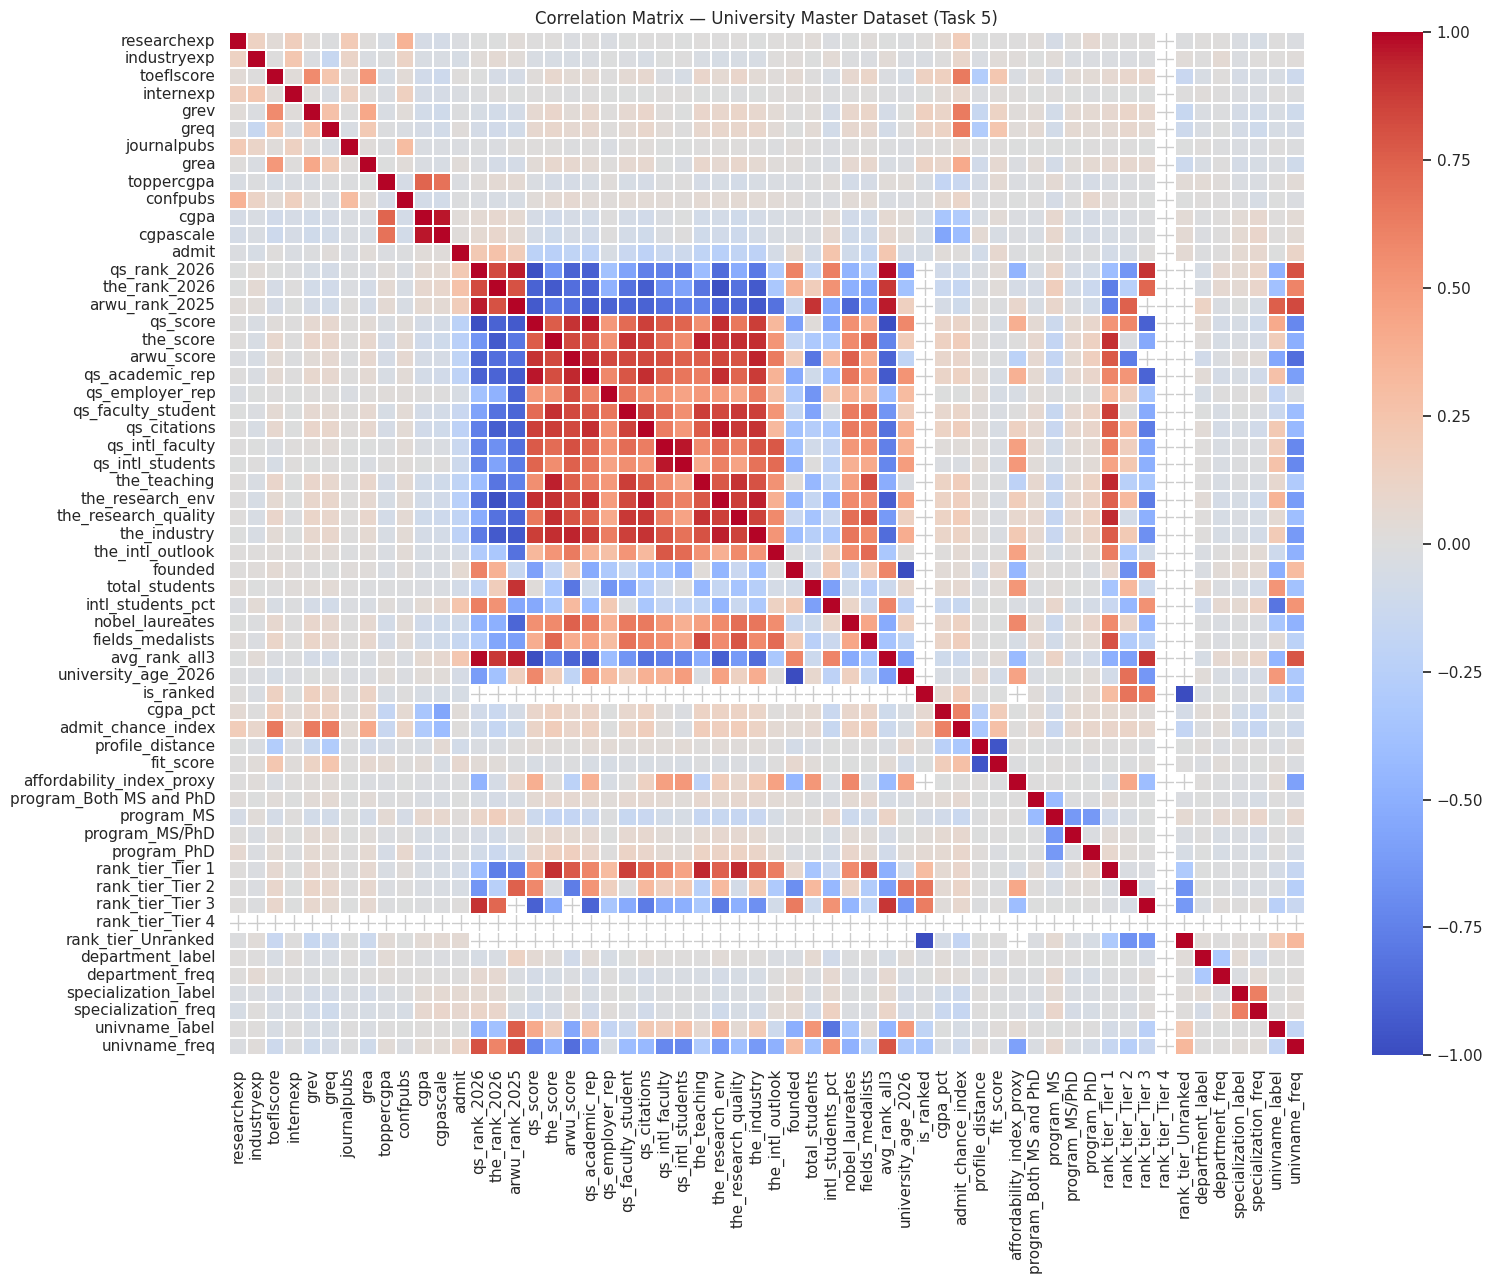

In [ ]:
numeric_uni = encoded_uni.select_dtypes(include=[np.number]).drop(columns=['serial_no'], errors='ignore')
corr_matrix_uni = numeric_uni.corr()

plt.figure(figsize=(16, 13))
sns.heatmap(corr_matrix_uni, cmap='coolwarm', center=0, linewidths=0.3,
            xticklabels=True, yticklabels=True)
plt.title('Correlation Matrix — University Master Dataset (Task 5)')
plt.tight_layout()
plt.savefig('correlation_matrix_university.png', dpi=150)
plt.show()


In [ ]:
# Only columns with no missing values are compared. Ranking columns exist for ~11% of rows,
# so their correlation would describe the 13 ranked universities only, not the whole dataset.
complete_cols = [c for c in numeric_uni.columns if numeric_uni[c].notna().all()]
corr_with_admit = corr_matrix_uni.loc[complete_cols, 'admit'].drop('admit').sort_values(key=abs, ascending=False)
print('Top correlations with admit (target):')
corr_with_admit.head(15)


Top correlations with admit (target):


,admit
univname_freq,0.111803
profile_distance,-0.080145
specialization_freq,0.075759
fit_score,0.075205
rank_tier_Tier 1,-0.072553
specialization_label,0.059032
industryexp,-0.049746
rank_tier_Unranked,0.047140
is_ranked,-0.047140
rank_tier_Tier 2,-0.043343


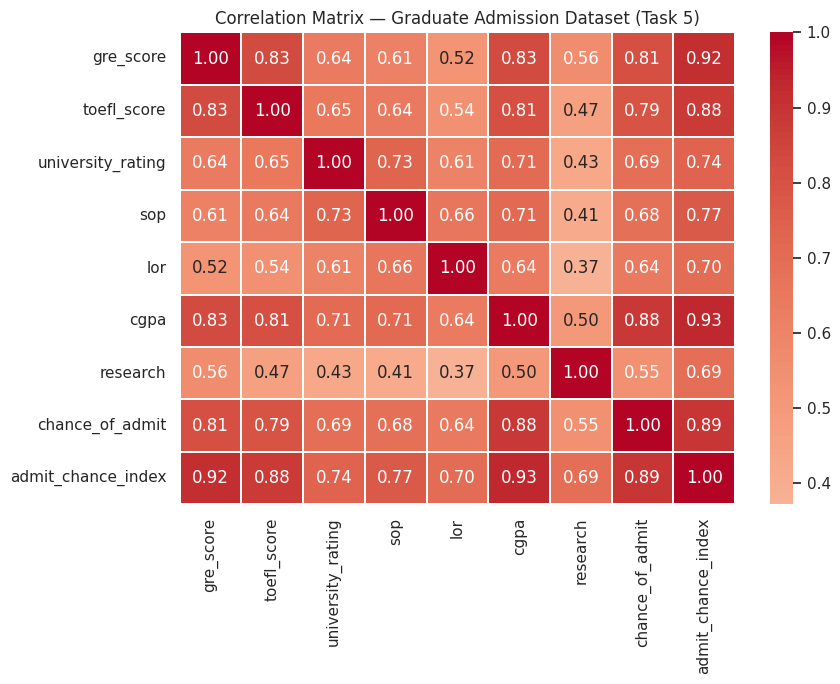

In [ ]:
numeric_grad = encoded_grad.select_dtypes(include=[np.number]).drop(columns=['serial_no'], errors='ignore')
corr_matrix_grad = numeric_grad.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix_grad, cmap='coolwarm', center=0, annot=True, fmt='.2f', linewidths=0.3)
plt.title('Correlation Matrix — Graduate Admission Dataset (Task 5)')
plt.tight_layout()
plt.savefig('correlation_matrix_graduate.png', dpi=150)
plt.show()


In [ ]:
corr_matrix_grad['chance_of_admit'].drop('chance_of_admit').sort_values(key=abs, ascending=False)


,chance_of_admit
admit_chance_index,0.893777
cgpa,0.882413
gre_score,0.810351
toefl_score,0.792228
university_rating,0.690132
sop,0.684137
lor,0.644737
research,0.545871


## 5. Feature Importance Ranking

Using a Random Forest against each dataset's target:
- Dataset A → `RandomForestClassifier` predicting `admit`
- Dataset B → `RandomForestRegressor` predicting `chance_of_admit`

Mutual information is computed alongside as a non-linear, model-free cross-check.

In [ ]:
# ---- Dataset A: RandomForestClassifier on admit ----
# Excluded from the feature set:
#  - identifiers / free text
#  - raw ranking columns: they exist for only ~11% of rows (NaN = not ranked); that information is
#    carried by `is_ranked` + `rank_tier_*` instead
#  - affordability_index_proxy: same reason (ranked rows only) - kept in the data for Tasks 3/9
#  - raw cgpa / cgpascale: different grading scales, replaced by the normalised `cgpa_pct`
ranking_raw_cols = ['qs_rank_2026', 'the_rank_2026', 'arwu_rank_2025', 'qs_score', 'the_score', 'arwu_score',
                    'qs_academic_rep', 'qs_employer_rep', 'qs_faculty_student', 'qs_citations', 'qs_intl_faculty',
                    'qs_intl_students', 'the_teaching', 'the_research_env', 'the_research_quality', 'the_industry',
                    'the_intl_outlook', 'founded', 'total_students', 'intl_students_pct', 'nobel_laureates',
                    'fields_medalists', 'avg_rank_all3', 'university_age_2026']
drop_cols_a = ['admit', 'username', 'userprofilelink', 'termandyear', 'ugcollege',
               'department', 'specialization', 'univname', 'journalpubs', 'confpubs',
               'cgpa', 'cgpascale', 'affordability_index_proxy'] + ranking_raw_cols
feature_cols_a = [c for c in numeric_uni.columns if c not in drop_cols_a]

train_mask = uni_df['split'] == 'train'
train_medians = numeric_uni.loc[train_mask, feature_cols_a].median()
X_a = numeric_uni[feature_cols_a].fillna(train_medians)
y_a = uni_df['admit']

# Importance is measured on TRAIN rows only, so feature selection never sees the test set
rf_clf = RandomForestClassifier(n_estimators=300, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1)
rf_clf.fit(X_a[train_mask], y_a[train_mask])

importance_a = pd.Series(rf_clf.feature_importances_, index=feature_cols_a).sort_values(ascending=False)

mi_a = pd.Series(
    mutual_info_classif(X_a[train_mask], y_a[train_mask], random_state=RANDOM_STATE),
    index=feature_cols_a
).sort_values(ascending=False)

feature_importance_report_a = pd.DataFrame({
    'rf_importance': importance_a,
    'mutual_info': mi_a.reindex(importance_a.index)
}).sort_values('rf_importance', ascending=False)

feature_importance_report_a.head(20)


,rf_importance,mutual_info
univname_freq,0.175120,0.063970
univname_label,0.142764,0.066500
cgpa_pct,0.089565,0.015916
admit_chance_index,0.075526,0.049555
profile_distance,0.064101,0.005796
fit_score,0.063595,0.005365
department_label,0.046252,0.010283
grev,0.044723,0.008501
toeflscore,0.040273,0.000000
greq,0.037304,0.000323


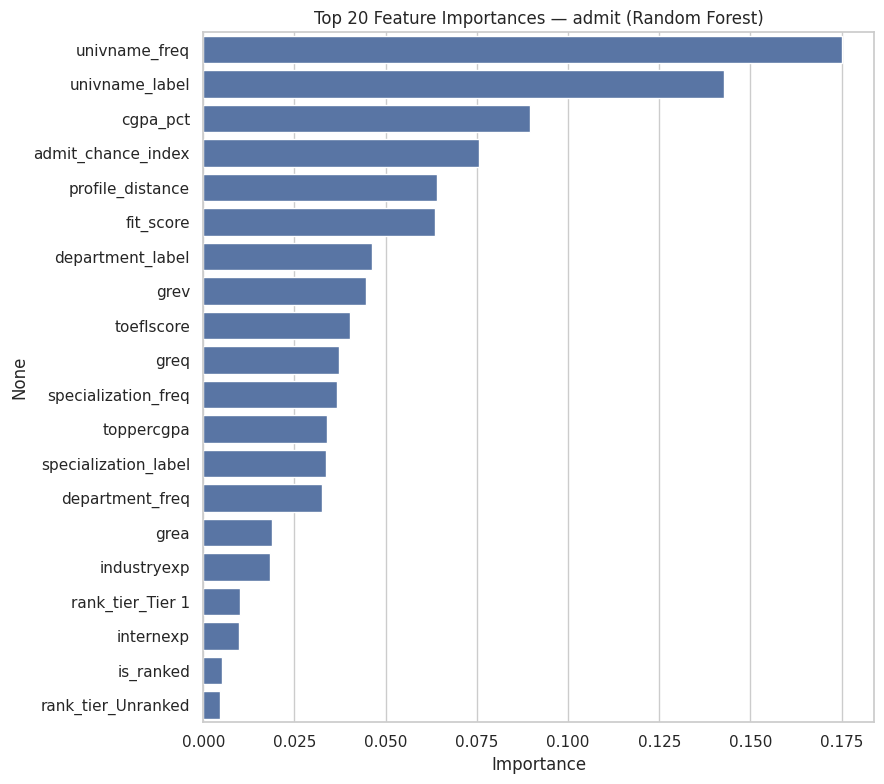

In [ ]:
plt.figure(figsize=(9, 8))
top_n = 20
sns.barplot(x=importance_a.head(top_n).values, y=importance_a.head(top_n).index, color='#4C72B0')
plt.title(f'Top {top_n} Feature Importances — admit (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance_university.png', dpi=150)
plt.show()


In [ ]:
# ---- Dataset B: RandomForestRegressor on chance_of_admit ----
feature_cols_b = [c for c in numeric_grad.columns if c != 'chance_of_admit']
X_b = numeric_grad[feature_cols_b]
y_b = numeric_grad['chance_of_admit']

rf_reg = RandomForestRegressor(n_estimators=300, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1)
rf_reg.fit(X_b, y_b)

importance_b = pd.Series(rf_reg.feature_importances_, index=feature_cols_b).sort_values(ascending=False)
mi_b = pd.Series(
    mutual_info_regression(X_b, y_b, random_state=RANDOM_STATE),
    index=feature_cols_b
).sort_values(ascending=False)

feature_importance_report_b = pd.DataFrame({
    'rf_importance': importance_b,
    'mutual_info': mi_b.reindex(importance_b.index)
}).sort_values('rf_importance', ascending=False)

feature_importance_report_b


,rf_importance,mutual_info
admit_chance_index,0.731895,1.039794
cgpa,0.183970,0.930767
gre_score,0.032547,0.642598
toefl_score,0.016108,0.581125
sop,0.014750,0.374362
lor,0.011466,0.267932
university_rating,0.007797,0.382829
research,0.001468,0.222463


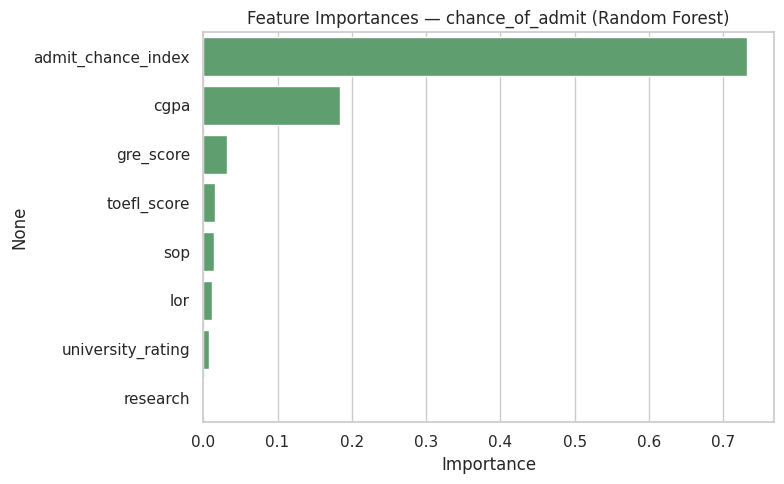

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(x=importance_b.values, y=importance_b.index, color='#55A868')
plt.title('Feature Importances — chance_of_admit (Random Forest)')
plt.xlabel('Importance')
plt.tight_layout()
plt.savefig('feature_importance_graduate.png', dpi=150)
plt.show()


## 6. Feature Selection

Rule applied: rank features by RF importance, keep the smallest top-ranked set whose
**cumulative importance covers 95%** of the total (falling back to at least 5 features
if fewer would meet that bar), then drop near-duplicates (pairwise |corr| > 0.90 with an
already-selected, higher-importance feature).

*Why not "importance ≥ mean importance" (the original rule)?* When one engineered feature
(e.g. `admit_chance_index`) dominates because it's a weighted combination of several raw
predictors also present in X, RF importance becomes extremely skewed — the mean sits far
above almost every individual feature, and the old rule collapsed to selecting a single
feature (see the Dataset B result before this fix: 1 of 12 features). The cumulative-importance
rule is far less sensitive to that kind of skew and yields a compact, non-degenerate feature set.


In [ ]:
def select_features(importance_series, corr_matrix, corr_threshold=0.90,
                     cum_importance=0.95, min_features=5):
    ranked = importance_series.sort_values(ascending=False)
    total = ranked.sum()
    cum_share = ranked.cumsum() / total if total > 0 else ranked.cumsum()

    # smallest top-N features covering `cum_importance` of total RF importance
    n_for_cum = int((cum_share < cum_importance).sum()) + 1
    n_for_cum = min(max(n_for_cum, min_features), len(ranked))
    candidates = ranked.head(n_for_cum).index.tolist()

    selected = []
    for feat in candidates:
        redundant = False
        for kept in selected:
            if feat in corr_matrix.columns and kept in corr_matrix.columns:
                if abs(corr_matrix.loc[feat, kept]) > corr_threshold:
                    redundant = True
                    break
        if not redundant:
            selected.append(feat)
    return selected

selected_features_a = select_features(importance_a, corr_matrix_uni, corr_threshold=0.90)
selected_features_b = select_features(importance_b, corr_matrix_grad, corr_threshold=0.90)

print(f'Dataset A: {len(selected_features_a)} / {len(feature_cols_a)} features selected')
print(selected_features_a)
print()
print(f'Dataset B: {len(selected_features_b)} / {len(feature_cols_b)} features selected')
print(selected_features_b)


Dataset A: 15 / 28 features selected
['univname_freq', 'univname_label', 'cgpa_pct', 'admit_chance_index', 'profile_distance', 'department_label', 'grev', 'toeflscore', 'greq', 'specialization_freq', 'toppercgpa', 'specialization_label', 'department_freq', 'grea', 'industryexp']

Dataset B: 3 / 8 features selected
['admit_chance_index', 'toefl_score', 'sop']


## 7. Deliverables

Writes all five Task 5 deliverables to `/content/task5_outputs/`:
1. `feature_engineering_report.md`
2. `feature_matrix_university.csv`, `feature_matrix_graduate.csv`
3. `correlation_matrix_university.csv`, `correlation_matrix_graduate.csv`
4. `feature_importance_university.csv`, `feature_importance_graduate.csv`
5. `selected_features.json`

In [ ]:
import os, json

out_dir = './task5_outputs'
os.makedirs(out_dir, exist_ok=True)

# 0. Full engineered table (includes affordability proxy & ranking columns for Tasks 3/9)
uni_df.to_csv(f'{out_dir}/university_features_full.csv', index=False)

# 1. Feature Matrix
feature_matrix_a = X_a.copy()
feature_matrix_a['admit'] = y_a.values
feature_matrix_a['split'] = uni_df['split'].values   # reused by Task 6 (fit_score was built from train rows only)
feature_matrix_a.to_csv(f'{out_dir}/feature_matrix_university.csv', index=False)

feature_matrix_b = X_b.copy()
feature_matrix_b['chance_of_admit'] = y_b.values
feature_matrix_b.to_csv(f'{out_dir}/feature_matrix_graduate.csv', index=False)

# 2. Correlation Matrix
corr_matrix_uni.to_csv(f'{out_dir}/correlation_matrix_university.csv')
corr_matrix_grad.to_csv(f'{out_dir}/correlation_matrix_graduate.csv')

# 3. Feature Importance Report
feature_importance_report_a.to_csv(f'{out_dir}/feature_importance_university.csv')
feature_importance_report_b.to_csv(f'{out_dir}/feature_importance_graduate.csv')

# 4. Selected Features
with open(f'{out_dir}/selected_features.json', 'w') as f:
    json.dump({
        'university_dataset': selected_features_a,
        'graduate_dataset': selected_features_b
    }, f, indent=2)

print('Saved deliverables to', out_dir)
os.listdir(out_dir)


Saved deliverables to ./task5_outputs


['feature_importance_graduate.csv',
 'feature_matrix_graduate.csv',
 'university_features_full.csv',
 'selected_features.json',
 'correlation_matrix_university.csv',
 'feature_engineering_report.md',
 'feature_importance_university.csv',
 'feature_matrix_university.csv',
 'correlation_matrix_graduate.csv']

In [ ]:
report = f'''# Feature Engineering Report — Task 5

## 1. Derived Features Created

**University Master dataset ({uni_df.shape[0]} rows):**
- `rank_tier` — Tier 1 (rank ≤ 10) / Tier 2 (11-25) / Tier 3 (26-50) / Tier 4 (> 50) from `{rank_col}`; 'Unranked' for universities not in the rankings file ({int(uni_df['is_ranked'].sum())} of {len(uni_df)} rows are ranked)
- `admit_chance_index` — weighted composite (0-1) of applicant CGPA%, GRE-Q/V, TOEFL, research & industry experience
- `fit_score` — inverse of the applicant's average z-distance from the admitted-cohort mean at their target university (1 = closest fit); cohort statistics computed from the training split only to avoid target leakage
- `affordability_index_proxy` — **proxy only**: no tuition/fee/country column exists in the source data, so this is built from institution scale (`total_students`), international-student share, and rank, for ranked universities only (NaN otherwise, excluded from the ML feature set) — it is NOT a true cost/affordability measure and should be replaced with real fee/country data if available

**Graduate Admission dataset ({grad_df.shape[0]} rows):**
- `admit_chance_index` — weighted composite (0-1) of GRE, TOEFL, CGPA, SOP, LOR, research, independent of the true `chance_of_admit` label (used as a sanity-check feature, correlates with but does not duplicate the label)
- `university_rating` (1-5) used directly as the ordinal rank tier

## 2. Encoding
- One-hot: `program`, `rank_tier` (university dataset); graduate dataset needs no encoding
- Label + frequency encoding: `department`, `specialization`, `univname` (high cardinality: {uni_df['department'].nunique()}, {uni_df['specialization'].nunique()}, {uni_df['univname'].nunique()} unique levels respectively)
- No `country` column exists in the source data, so no country encoding was performed — see note in Section 1 of the notebook for how to add one later

## 3. Correlation Analysis
- Full correlation matrices computed for both datasets (see `correlation_matrix_university.csv`, `correlation_matrix_graduate.csv`)
- Top correlate with `admit` (university dataset): {corr_with_admit.index[0]} (r={corr_with_admit.iloc[0]:.3f})
- Top correlate with `chance_of_admit` (graduate dataset): {corr_matrix_grad['chance_of_admit'].drop('chance_of_admit').abs().idxmax()}

## 4. Feature Importance
- Random Forest + mutual information computed for both datasets
- Top 5 features (university, by RF importance): {list(importance_a.head(5).index)}
- Top 5 features (graduate, by RF importance): {list(importance_b.head(5).index)}

## 5. Feature Selection
- Rule: smallest top-ranked set covering 95% of cumulative RF importance (minimum 5), then drop any feature with |corr| > 0.90 to an already-selected one. Importance for the university dataset was measured on the training split only
- University dataset: {len(selected_features_a)} of {len(feature_cols_a)} features retained
- Graduate dataset: {len(selected_features_b)} of {len(feature_cols_b)} features retained

## Known Limitations (be upfront about these in the report / viva)
- No tuition/fee or country column in the merged dataset → Affordability Index is a resource-availability proxy, not real cost
- Only a small share of applicant rows match a ranked university, so ranking-based features carry limited signal
- `department`/`specialization` are extremely high-cardinality free-text fields — label/frequency encoding was used instead of one-hot to keep the matrix usable; this may lose some information a more careful text-embedding approach could capture
'''

with open(f'{out_dir}/feature_engineering_report.md', 'w') as f:
    f.write(report)

print(report)


# Feature Engineering Report — Task 5

## 1. Derived Features Created

**University Master dataset (53527 rows):**
- `rank_tier` — Tier 1 (rank ≤ 10) / Tier 2 (11-25) / Tier 3 (26-50) / Tier 4 (> 50) from `avg_rank_all3`; 'Unranked' for universities not in the rankings file (5695 of 53527 rows are ranked)
- `admit_chance_index` — weighted composite (0-1) of applicant CGPA%, GRE-Q/V, TOEFL, research & industry experience
- `fit_score` — inverse of the applicant's average z-distance from the admitted-cohort mean at their target university (1 = closest fit); cohort statistics computed from the training split only to avoid target leakage
- `affordability_index_proxy` — **proxy only**: no tuition/fee/country column exists in the source data, so this is built from institution scale (`total_students`), international-student share, and rank, for ranked universities only (NaN otherwise, excluded from the ML feature set) — it is NOT a true cost/affordability measure and should be replaced with r

In [ ]:
# Zip all Task 5 deliverables
import shutil
shutil.make_archive('task5_deliverables', 'zip', out_dir)

try:
    from google.colab import files
    files.download('task5_deliverables.zip')
except ModuleNotFoundError:
    print("Saved 'task5_deliverables.zip' in the current working directory.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>